# DBA5106 Project 2 · Which HDB listings deserve the premium marketing package?

**Version 2: With Data.** A classification project following every step of the Project Requirements:

| Project Requirements step | Section |
|---|---|
| 1. Problem framing and customized evaluation loss | §1 |
| Dataset choice and train / validation / test split | §2 |
| 2–3. Glassbox + blackbox models, each with L2 and a surrogate loss, tuned separately | §3 |
| 4. Model selection on validation AUC | §4 |
| 6. Calibration: bins, reliability diagram, ECE, Platt scaling | §5 |
| 5. Threshold that minimises the evaluation loss | §6 |
| 7. Tree SHAP, global and local | §7 |

> **Order note.** We calibrate (§5) *before* tuning the threshold (§6), so the threshold is chosen on calibrated probabilities. That is what lets us compare it with the decision-theory value 1 / (1 + 3) = 0.25.

**How to run.** Put `resaleprice.csv` (HDB "Resale flat prices based on registration date from Jan-2017 onwards", data.gov.sg) in the same folder as this notebook, then *Run All*. Packages: `pandas numpy scikit-learn matplotlib shap`. Full run takes about 5 minutes, mostly gradient boosting tuning.

## 0 · Setup
Imports and the few settings that drive every later step. Change `FN_COST` to rerun the whole analysis under a different cost assumption.

In [1]:
# !pip install shap   # uncomment if shap is not installed

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# scikit-learn >= 1.8 warns that penalty="l1" is deprecated in favour of l1_ratio.
# We keep penalty="l1" because it behaves correctly on older versions too (e.g. Colab), and hide only these warnings.
warnings.filterwarnings("ignore", message=".*'penalty' was deprecated.*")
warnings.filterwarnings("ignore", message=".*Inconsistent values: penalty=l1.*")

from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

CSV_PATH = "resaleprice.csv"   # HDB resale data from data.gov.sg
SEED = 5106                    # one seed for every random step, so results are reproducible
FP_COST = 1.0                  # cost of a false positive: premium package wasted on a non-premium flat
FN_COST = 3.0                  # cost of a false negative: premium flat under-marketed (lost commission, unhappy seller)
rng = np.random.default_rng(SEED)

# Chart style shared by every figure (matches the slide deck)
NAVY, ORANGE, GREY, BG, GRID = "#15233F", "#B04E17", "#5A6472", "#FCFBF8", "#DEDBD3"
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG})

## 1 · Problem framing and evaluation loss

**Decision context.** When a seller lists a 4-room HDB flat, a property agency decides at sign-up, before any price is known, whether to give the listing its *premium marketing package*: professional photos, featured online ads and a senior agent. Our model scores each listing; if P(premium) ≥ t, the flat gets the package.

**Target.** `premium = 1` if the flat's price per sqm is above the **median for 4-room sales in the same town and quarter**, else 0. Defining it relative to comparable flats keeps the classes balanced (~50/50), removes location and market-timing effects, and avoids a near-perfectly predictable target.

**Customized loss** (deviates from misclassification loss because the two errors cost different amounts):

| | Package given | Standard service |
|---|---|---|
| **Actually premium** | 0 | **3** (FN: under-marketed premium flat) |
| **Not premium** | **1** (FP: wasted package) | 0 |

$$L(t) = \frac{1\cdot FP(t) + 3\cdot FN(t)}{n}$$

With calibrated probabilities, flag when $3p > 1-p$, i.e. $p > 1/(1+3) = 0.25$.

In [2]:
def evaluation_loss(p, y, t, fn_cost=FN_COST, fp_cost=FP_COST):
    # Average cost per flat when flats with probability p >= t receive the premium package.
    flagged = p >= t
    fp = np.sum(flagged & (y == 0))      # package given, flat not premium
    fn = np.sum(~flagged & (y == 1))     # premium flat missed
    return (fp_cost * fp + fn_cost * fn) / len(y)

def confusion(p, y, t):
    # Confusion-matrix counts at threshold t, for reporting.
    flagged = p >= t
    return {"TP": int(np.sum(flagged & (y == 1))), "FP": int(np.sum(flagged & (y == 0))),
            "FN": int(np.sum(~flagged & (y == 1))), "TN": int(np.sum(~flagged & (y == 0)))}

print("Theoretical cost-minimising threshold:", FP_COST / (FP_COST + FN_COST))

Theoretical cost-minimising threshold: 0.25


## 2 · Data, target, features and split

### 2a · Load and filter
We keep **4-room flats** (the most common type, so every flat is compared with genuinely similar flats) sold from **January 2023** onwards (current market, moderate size). The dataset has no missing values.

In [3]:
raw = pd.read_csv(CSV_PATH)
print(f"Full file: {len(raw):,} rows, {raw.month.min()} to {raw.month.max()}, missing values: {raw.isna().sum().sum()}")
print(raw.flat_type.value_counts(normalize=True).round(3).to_string())

d = raw[(raw.flat_type == "4 ROOM") & (raw.month >= "2023-01")].copy()
print(f"\nKept: {len(d):,} 4-room sales, {d.month.min()} to {d.month.max()}")
d.head()

Full file: 244,539 rows, 2017-01 to 2026-11, missing values: 0
flat_type
4 ROOM              0.425
5 ROOM              0.245
3 ROOM              0.237
EXECUTIVE           0.071
2 ROOM              0.021
MULTI-GENERATION    0.000
1 ROOM              0.000

Kept: 43,978 4-room sales, 2023-01 to 2026-11


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
143456,2023-01,ANG MO KIO,4 ROOM,128,ANG MO KIO AVE 3,04 TO 06,92.0,New Generation,1978,54 years 09 months,440000.0
143458,2023-01,ANG MO KIO,4 ROOM,612,ANG MO KIO AVE 4,01 TO 03,91.0,New Generation,1980,56 years 08 months,450000.0
143459,2023-01,ANG MO KIO,4 ROOM,428,ANG MO KIO AVE 3,04 TO 06,92.0,New Generation,1978,54 years 11 months,460000.0
143460,2023-01,ANG MO KIO,4 ROOM,154,ANG MO KIO AVE 5,07 TO 09,93.0,New Generation,1981,57 years,466888.0
143461,2023-01,ANG MO KIO,4 ROOM,467,ANG MO KIO AVE 10,07 TO 09,92.0,New Generation,1979,55 years 11 months,470000.0


### 2b · Target: premium vs not premium
Price per sqm is compared with the median of the **same town and quarter**, so the label is balanced by construction and immune to overall price growth.

In [4]:
d["date"] = pd.to_datetime(d.month)
d["year"] = d.date.dt.year
d["quarter"] = d.date.dt.to_period("Q").astype(str)
d["ppsqm"] = d.resale_price / d.floor_area_sqm

town_quarter_median = d.groupby(["town", "quarter"]).ppsqm.transform("median")
d["premium"] = (d.ppsqm > town_quarter_median).astype(int)

print(f"Premium share: {d.premium.mean():.1%}")
d.groupby("year").premium.mean().round(3)

Premium share: 49.6%


year
2023    0.496
2024    0.496
2025    0.497
2026    0.496
Name: premium, dtype: float64

### 2c · Features an agent knows at sign-up
| Feature | Built from | How |
|---|---|---|
| `storey` | `storey_range` | midpoint, e.g. "10 TO 12" → 11 |
| `area` | `floor_area_sqm` | as is |
| `lease` | `remaining_lease` | "61 years 04 months" → 61.33 |
| `model_*` | `flat_model` | 7 groups, rare models pooled |
| `region_*`, `mature` | `town` | 5 regions + mature-estate flag |

**Deliberately excluded:** price, price per sqm and medians (they define the target → leakage); block and street (nearly identify the flat → near-perfect prediction); lease commencement year (duplicates `lease`); town itself (the target is already relative to town).

In [5]:
def lease_years(text):
    # Convert '61 years 04 months' (or '61 years') to decimal years.
    parts = text.split()
    years = int(parts[0])
    months = int(parts[2]) if len(parts) >= 4 else 0
    return years + months / 12

d["storey"] = d.storey_range.str.split(" TO ").apply(lambda r: (int(r[0]) + int(r[1])) / 2)
d["lease"] = d.remaining_lease.apply(lease_years)
d["area"] = d.floor_area_sqm

# Flat model: merge near-identical designs, pool very rare ones into 'Other'
MODEL_GROUP = {"Model A": "Model A", "Model A2": "Model A",
               "Premium Apartment": "Premium Apt", "Premium Apartment Loft": "Premium Apt",
               "New Generation": "New Generation", "Simplified": "Simplified", "Improved": "Improved",
               "DBSS": "DBSS/S1", "Type S1": "DBSS/S1"}
d["model_grp"] = d.flat_model.map(MODEL_GROUP).fillna("Other")

# Town -> planning region, and HDB mature-estate flag
REGION = {"Central": ["BISHAN", "BUKIT MERAH", "BUKIT TIMAH", "CENTRAL AREA", "GEYLANG",
                      "KALLANG/WHAMPOA", "MARINE PARADE", "QUEENSTOWN", "TOA PAYOH"],
          "East": ["BEDOK", "PASIR RIS", "TAMPINES"],
          "North": ["SEMBAWANG", "WOODLANDS", "YISHUN"],
          "North-East": ["ANG MO KIO", "HOUGANG", "PUNGGOL", "SENGKANG", "SERANGOON"],
          "West": ["BUKIT BATOK", "BUKIT PANJANG", "CHOA CHU KANG", "CLEMENTI", "JURONG EAST", "JURONG WEST"]}
d["region"] = d.town.map({t: r for r, towns in REGION.items() for t in towns})
MATURE = {"ANG MO KIO", "BEDOK", "BISHAN", "BUKIT MERAH", "BUKIT TIMAH", "CENTRAL AREA", "CLEMENTI",
          "GEYLANG", "KALLANG/WHAMPOA", "MARINE PARADE", "PASIR RIS", "QUEENSTOWN", "SERANGOON",
          "TAMPINES", "TOA PAYOH"}
d["mature"] = d.town.isin(MATURE).astype(int)
assert d.region.notna().all(), "every town must map to a region"

# One-hot encode categories; drop one reference level each (Model A, Central) so LASSO coefficients read as 'vs reference'
X = pd.concat([d[["storey", "area", "lease", "mature"]],
               pd.get_dummies(d.model_grp, prefix="model").astype(int),
               pd.get_dummies(d.region, prefix="region").astype(int)], axis=1)
X = X.drop(columns=["model_Model A", "region_Central"])
FEATURES = list(X.columns)
y = d.premium.values
print(len(FEATURES), "features:", FEATURES)
d[["storey", "area", "lease", "mature"]].describe().round(1)

14 features: ['storey', 'area', 'lease', 'mature', 'model_DBSS/S1', 'model_Improved', 'model_New Generation', 'model_Other', 'model_Premium Apt', 'model_Simplified', 'region_East', 'region_North', 'region_North-East', 'region_West']


,storey,area,lease,mature
count,43978.0,43978.0,43978.0,43978.0
mean,9.2,94.9,76.6,0.4
std,6.4,6.7,14.1,0.5
min,2.0,70.0,40.4,0.0
25%,5.0,92.0,62.9,0.0
50%,8.0,93.0,76.2,0.0
75%,11.0,100.0,90.8,1.0
max,50.0,176.0,96.2,1.0


### 2d · Train / validation / test split, by time
Train on 2023–2024, validate on 2025, test on 2026: the agency learns from past sales and scores new listings, and a random split would leak future prices.

Validation is further split into two random halves so no step reuses the same rows: **half A** fits Platt scaling, **half B** judges calibration and tunes the threshold. The test set is used once, at the end.

In [6]:
is_train = (d.year <= 2024).values
is_val = (d.year == 2025).values
is_test = (d.year == 2026).values
X_tr, X_va, X_te = X[is_train], X[is_val], X[is_test]
y_tr, y_va, y_te = y[is_train], y[is_val], y[is_test]

# Random halves of the validation set
order = np.arange(len(y_va)); rng.shuffle(order)
half_A = np.zeros(len(y_va), bool); half_A[order[: len(order) // 2]] = True
half_B = ~half_A

pd.DataFrame({"rows": [len(y_tr), len(y_va), len(y_te)],
              "premium share": [y_tr.mean(), y_va.mean(), y_te.mean()]},
             index=["train 2023-24", "validation 2025", "test 2026"]).round(3)

,rows,premium share
train 2023-24,23345,0.496
validation 2025,10843,0.497
test 2026,9790,0.496


## 3 · Models: glassbox vs blackbox, two training losses each

| | L2 loss (squared error on 0/1) | Surrogate: binomial deviance (log loss) |
|---|---|---|
| **LASSO** (glassbox) | `Lasso` | `LogisticRegression(penalty="l1")` |
| **Gradient boosting** (blackbox, tree-based) | `GradientBoostingRegressor(loss="squared_error")` | `GradientBoostingClassifier(loss="log_loss")` |

Each of the four versions is **tuned separately on validation AUC**, with deliberately small grids (the Project Requirements: *think more, try less*). LASSO needs standardised features; trees do not. AUC depends only on ranking, so it is fair to L2 versions whose scores can fall outside [0, 1].

In [7]:
scaler = StandardScaler().fit(X_tr)          # fitted on training data only
def standardise(Z):
    return scaler.transform(Z)

def raw_score(model, name, Z):
    # Model output used for AUC: L2 versions give a regression score, deviance versions a probability.
    Zin = standardise(Z) if name.startswith("LASSO") else Z
    return model.predict(Zin) if "L2" in name else model.predict_proba(Zin)[:, 1]

def tune(name, make_model, grid):
    # Fit one model per grid point on train, score validation AUC, keep the best.
    best_auc, best_params, best_model, log = -1, None, None, []
    Ztr = standardise(X_tr) if name.startswith("LASSO") else X_tr
    for params in grid:
        model = make_model(**params).fit(Ztr, y_tr)
        auc = roc_auc_score(y_va, raw_score(model, name, X_va))
        log.append({**params, "val_auc": round(auc, 4)})
        if auc > best_auc:
            best_auc, best_params, best_model = auc, params, model
    print(f"{name:18s} best {best_params}  validation AUC = {best_auc:.4f}")
    return best_model, best_auc, best_params, pd.DataFrame(log)

lasso_l2_grid = [{"alpha": a} for a in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2)]
lasso_dev_grid = [{"C": c} for c in (0.001, 0.003, 0.01, 0.03, 0.1, 1.0)]   # C = 1 / penalty strength
gb_grid = [{"n_estimators": n, "learning_rate": lr, "max_depth": md}
           for n in (100, 300) for lr in (0.05, 0.1) for md in (2, 3, 4)]   # 12 settings

SPECS = {
    "LASSO · L2":       (lambda **p: Lasso(max_iter=5000, **p), lasso_l2_grid),
    "LASSO · deviance": (lambda **p: LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000, **p), lasso_dev_grid),
    "GB · L2":          (lambda **p: GradientBoostingRegressor(loss="squared_error", random_state=SEED, **p), gb_grid),
    "GB · deviance":    (lambda **p: GradientBoostingClassifier(loss="log_loss", random_state=SEED, **p), gb_grid),
}
models, val_auc, best_params, tuning_logs = {}, {}, {}, {}
for name, (make_model, grid) in SPECS.items():
    models[name], val_auc[name], best_params[name], tuning_logs[name] = tune(name, make_model, grid)

LASSO · L2         best {'alpha': 0.0001}  validation AUC = 0.8768
LASSO · deviance   best {'C': 1.0}  validation AUC = 0.8783
GB · L2            best {'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 4}  validation AUC = 0.8988
GB · deviance      best {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4}  validation AUC = 0.8993


In [8]:
# Full tuning log for the blackbox deviance model (the eventual winner)
tuning_logs["GB · deviance"].sort_values("val_auc", ascending=False).head(6)

,n_estimators,learning_rate,max_depth,val_auc
8,300,0.05,4,0.8993
11,300,0.10,4,0.8988
10,300,0.10,3,0.8984
5,100,0.10,4,0.8981
7,300,0.05,3,0.8966
9,300,0.10,2,0.8950


## 4 · Model selection on validation AUC
Rule **fixed before looking at results**: take the highest validation AUC, but prefer LASSO if it is within 0.01 of the best, because an agent can explain its coefficients. Test AUC is shown only to confirm we did not overfit validation; it plays no part in the choice.

In [9]:
MARGIN = 0.01
best_overall = max(val_auc, key=val_auc.get)
best_lasso = max([n for n in val_auc if n.startswith("LASSO")], key=val_auc.get)
gap = val_auc[best_overall] - val_auc[best_lasso]
FINAL = best_lasso if gap <= MARGIN else best_overall

summary = pd.DataFrame({"validation AUC": val_auc,
                        "test AUC": {n: roc_auc_score(y_te, raw_score(m, n, X_te)) for n, m in models.items()},
                        "best params": best_params}).round(3)
print(f"Gap between best model and best LASSO: {gap:.3f}  ->  final model: {FINAL}")
summary

Gap between best model and best LASSO: 0.021  ->  final model: GB · deviance


,validation AUC,test AUC,best params
LASSO · L2,0.877,0.876,{'alpha': 0.0001}
LASSO · deviance,0.878,0.876,{'C': 1.0}
GB · L2,0.899,0.885,"{'n_estimators': 300, 'learning_rate': 0.1, 'm..."
GB · deviance,0.899,0.891,"{'n_estimators': 300, 'learning_rate': 0.05, '..."


## 5 · Calibration: bins, reliability diagram, ECE and Platt scaling
For **all four** versions:
1. **Bin evaluation**: 10 equal-width bins of predicted probability; compare mean prediction with the observed premium rate per bin.
2. **Reliability diagram**: plot the two; a calibrated model lies on the diagonal.
3. **ECE** = Σ (n_b / n) · |observed rate_b − mean prediction_b|.
4. **Platt scaling**: a one-variable logistic regression on the model's raw decision score (the L2 output, or the log-odds for deviance models), fitted on validation **half A**, judged on **half B**. Platt is kept only if it lowers ECE.

In [10]:
def ece_bins(p, y, n_bins=10):
    # Expected calibration error plus per-bin (mean prediction, observed rate, count).
    p = np.clip(p, 0, 1)
    edges = np.linspace(0, 1, n_bins + 1)
    ece, rows = 0.0, []
    for i in range(n_bins):
        upper = (p < edges[i + 1]) if i < n_bins - 1 else (p <= 1)
        in_bin = (p >= edges[i]) & upper
        if in_bin.sum() == 0:
            continue
        gap = abs(y[in_bin].mean() - p[in_bin].mean())
        ece += in_bin.sum() / len(p) * gap
        rows.append({"pred": p[in_bin].mean(), "obs": y[in_bin].mean(), "n": int(in_bin.sum())})
    return ece, pd.DataFrame(rows)

def decision_score(name, Z):
    # Input to Platt scaling: L2 regression output, or log-odds for deviance models.
    if "L2" in name:
        return raw_score(models[name], name, Z)
    m = models[name]
    return m.decision_function(standardise(Z) if name.startswith("LASSO") else Z)

platt, use_platt, calib, bins = {}, {}, {}, {}
for name in models:
    s_val = decision_score(name, X_va)
    platt[name] = LogisticRegression(C=1e6, max_iter=1000).fit(s_val[half_A].reshape(-1, 1), y_va[half_A])
    before = raw_score(models[name], name, X_va)[half_B]                       # uncalibrated scores on half B
    after = platt[name].predict_proba(s_val[half_B].reshape(-1, 1))[:, 1]       # Platt-calibrated on half B
    (e0, b0), (e1, b1) = ece_bins(before, y_va[half_B]), ece_bins(after, y_va[half_B])
    use_platt[name] = e1 < e0
    bins[name] = (b0, b1)
    calib[name] = {"ECE before": e0, "ECE after Platt": e1, "Platt used": use_platt[name],
                   "Platt slope": platt[name].coef_[0, 0], "Platt intercept": platt[name].intercept_[0]}

def calibrated_prob(name, Z):
    # Final probability for a model: Platt-calibrated if that helped, else the clipped raw score.
    if use_platt[name]:
        return platt[name].predict_proba(decision_score(name, Z).reshape(-1, 1))[:, 1]
    return np.clip(raw_score(models[name], name, Z), 0, 1)

pd.DataFrame(calib).T.round(3)

,ECE before,ECE after Platt,Platt used,Platt slope,Platt intercept
LASSO · L2,0.057897,0.02248,True,6.066467,-2.910493
LASSO · deviance,0.032464,0.026234,True,0.983961,0.09052
GB · L2,0.027175,0.01818,True,5.743588,-2.834376
GB · deviance,0.02195,0.019206,True,1.017215,0.030315


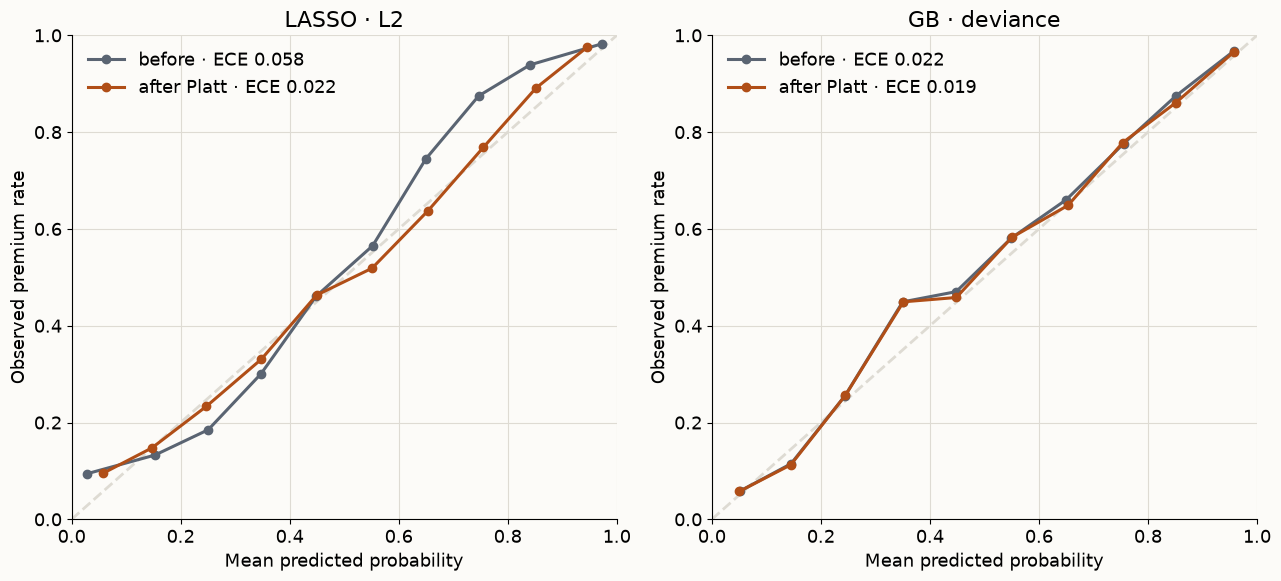

In [11]:
# Reliability diagrams: the worst-calibrated version and the final model, before vs after Platt
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, name in zip(axes, ["LASSO · L2", FINAL]):
    b0, b1 = bins[name]
    ax.plot([0, 1], [0, 1], ls="--", color=GRID, lw=2)
    ax.plot(b0.pred, b0.obs, "o-", color=GREY, lw=2.2, label=f"before · ECE {calib[name]['ECE before']:.3f}")
    ax.plot(b1.pred, b1.obs, "o-", color=ORANGE, lw=2.2, label=f"after Platt · ECE {calib[name]['ECE after Platt']:.3f}")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed premium rate", title=name)
    ax.legend(loc="upper left", frameon=False); ax.grid(color=GRID)
plt.tight_layout(); plt.savefig("reliability.png", dpi=150); plt.show()

## 6 · Threshold that minimises the evaluation loss
Sweep t from 0.01 to 0.99 on validation **half B** using the final model's calibrated probabilities, pick the t with the lowest L(t), then report on the untouched **test** set against the default 0.5. A sensitivity check repeats this for 2:1 and 5:1 cost ratios.

In [12]:
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
p_val_B = calibrated_prob(FINAL, X_va)[half_B]
y_val_B = y_va[half_B]
val_curve = np.array([evaluation_loss(p_val_B, y_val_B, t) for t in thresholds])
T_STAR = float(thresholds[val_curve.argmin()])

p_test = calibrated_prob(FINAL, X_te)
results = pd.DataFrame({
    "tuned t": [T_STAR, evaluation_loss(p_test, y_te, T_STAR), np.mean(p_test >= T_STAR), *confusion(p_test, y_te, T_STAR).values()],
    "default t = 0.5": [0.5, evaluation_loss(p_test, y_te, 0.5), np.mean(p_test >= 0.5), *confusion(p_test, y_te, 0.5).values()],
}, index=["threshold", "test cost per flat", "share flagged", "TP", "FP", "FN", "TN"])
print(f"Tuned threshold {T_STAR} (theory {FP_COST / (FP_COST + FN_COST):.2f}); "
      f"naive rules on test: flag all = {evaluation_loss(np.ones_like(p_test), y_te, 0.5):.3f}, "
      f"flag none = {evaluation_loss(np.zeros_like(p_test), y_te, 0.5):.3f}")
results.round(3)

Tuned threshold 0.27 (theory 0.25); naive rules on test: flag all = 0.504, flag none = 1.488


,tuned t,default t = 0.5
threshold,0.270,0.500
test cost per flat,0.328,0.406
share flagged,0.609,0.471
TP,4331.000,3801.000
FP,1629.000,809.000
FN,526.000,1056.000
TN,3304.000,4124.000


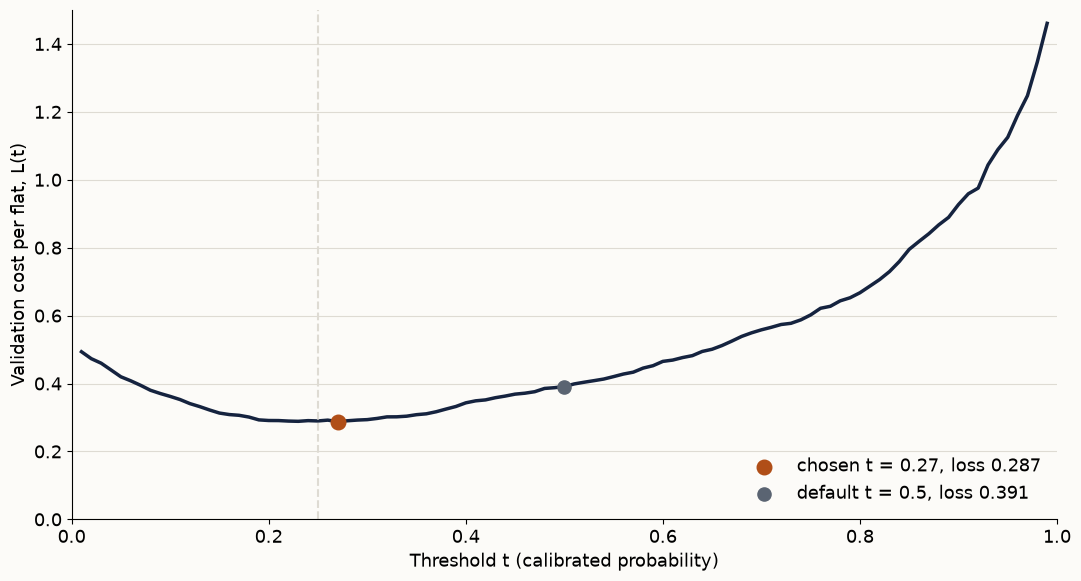

In [13]:
# L(t) curve on validation half B
best_loss, loss_05 = val_curve.min(), val_curve[thresholds == 0.5][0]
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(thresholds, val_curve, color=NAVY, lw=2.5)
ax.axvline(FP_COST / (FP_COST + FN_COST), color=GRID, ls="--", lw=1.5)
ax.scatter([T_STAR], [best_loss], color=ORANGE, s=110, zorder=3, label=f"chosen t = {T_STAR:.2f}, loss {best_loss:.3f}")
ax.scatter([0.5], [loss_05], color=GREY, s=90, zorder=3, label=f"default t = 0.5, loss {loss_05:.3f}")
ax.set(xlabel="Threshold t (calibrated probability)", ylabel="Validation cost per flat, L(t)", xlim=(0, 1), ylim=(0, 1.5))
ax.legend(frameon=False); ax.grid(axis="y", color=GRID)
plt.tight_layout(); plt.savefig("threshold.png", dpi=150); plt.show()

In [14]:
# Sensitivity: does the recommendation survive other cost ratios?
rows = []
for ratio in (2, 3, 5):
    curve = [evaluation_loss(p_val_B, y_val_B, t, fn_cost=ratio) for t in thresholds]
    t_r = float(thresholds[int(np.argmin(curve))])
    rows.append({"FN:FP": f"{ratio}:1", "tuned t": t_r, "theory 1/(1+r)": round(1 / (1 + ratio), 3),
                 "test cost at tuned t": evaluation_loss(p_test, y_te, t_r, fn_cost=ratio),
                 "test cost at 0.5": evaluation_loss(p_test, y_te, 0.5, fn_cost=ratio)})
pd.DataFrame(rows).round(3)

,FN:FP,tuned t,theory 1/(1+r),test cost at tuned t,test cost at 0.5
0,2:1,0.30,0.333,0.272,0.298
1,3:1,0.27,0.250,0.328,0.406
2,5:1,0.19,0.167,0.386,0.622


## 7 · Tree SHAP on the tree-based blackbox (global and local)
Required by the Project Requirements even if the final model were LASSO. We explain `GB · deviance` on a random sample of 3,000 test flats; SHAP values are in **log-odds of premium**. Region and flat-model effects are relative to the dropped reference levels (Central, Model A).

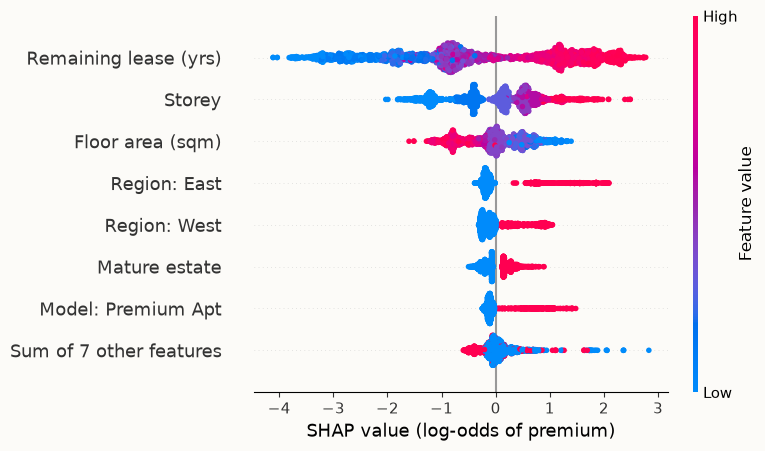

In [15]:
gb = models["GB · deviance"]
explainer = shap.TreeExplainer(gb)
sample = rng.choice(len(X_te), size=min(3000, len(X_te)), replace=False)
X_sample = X_te.iloc[sample]
sv = explainer(X_sample)

readable = {"storey": "Storey", "area": "Floor area (sqm)", "lease": "Remaining lease (yrs)", "mature": "Mature estate"}
sv.feature_names = [readable.get(f, f.replace("model_", "Model: ").replace("region_", "Region: ")) for f in FEATURES]

# Global: which features move predictions most, and in which direction
shap.plots.beeswarm(sv, max_display=8, show=False)
plt.xlabel("SHAP value (log-odds of premium)"); plt.tight_layout(); plt.savefig("shap_global.png", dpi=150); plt.show()

JURONG WEST, 2026-11, storey 13 TO 15, 108 sqm, 68.4 yrs lease, Model A; sold $530,000 ($4,907/sqm) -> premium = 1, calibrated P = 0.267 < t = 0.27


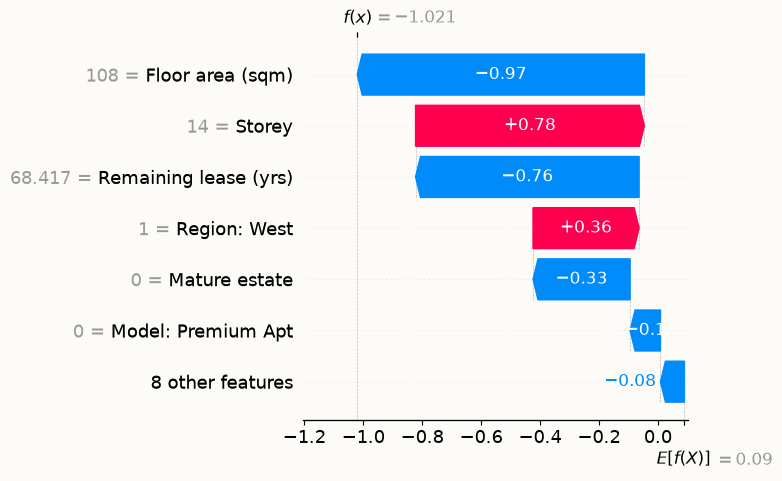

In [16]:
# Local: explain one premium flat the final model MISSES at the tuned threshold (closest to the threshold)
p_sample, y_sample = calibrated_prob(FINAL, X_sample), y_te[sample]
missed = np.where((p_sample < T_STAR) & (y_sample == 1))[0]
case = int(missed[np.argmax(p_sample[missed])])

flat = d[is_test].iloc[sample[case]]
print(f"{flat.town}, {flat.month}, storey {flat.storey_range}, {flat.area:.0f} sqm, {flat.lease:.1f} yrs lease, "
      f"{flat.flat_model}; sold ${flat.resale_price:,.0f} (${flat.ppsqm:,.0f}/sqm) -> premium = 1, "
      f"calibrated P = {p_sample[case]:.3f} < t = {T_STAR}")

shap.plots.waterfall(sv[case], max_display=7, show=False)
plt.tight_layout(); plt.savefig("shap_local.png", dpi=150); plt.show()

In [17]:
# Cross-check: does the blackbox tell the same story as the glassbox?
lasso_coef = pd.Series(models["LASSO · deviance"].coef_.ravel(), index=FEATURES)
compare = pd.DataFrame({"mean |SHAP| (GB)": np.abs(sv.values).mean(axis=0),
                        "LASSO coef (standardised)": lasso_coef.values}, index=FEATURES)
compare.sort_values("mean |SHAP| (GB)", ascending=False).round(3)

,mean |SHAP| (GB),LASSO coef (standardised)
lease,1.461,1.681
storey,0.639,0.827
area,0.436,-0.305
region_East,0.319,0.616
region_West,0.249,1.201
mature,0.210,1.059
model_Premium Apt,0.188,0.194
region_North-East,0.145,0.681
region_North,0.075,1.017
model_DBSS/S1,0.030,0.252


## 8 · Team decisions, filled from the results above

In [18]:
c = calib[FINAL]
pd.DataFrame([
    ("Dataset", f"HDB resale prices (data.gov.sg): 4-room, {d.month.min()} to {d.month.max()}, {len(d):,} rows"),
    ("Target / classes", f"premium = price/sqm above town x quarter median; {y.mean():.1%} positive"),
    ("Decision context", "Agency gives flagged listings the premium marketing package"),
    ("Evaluation loss", f"FP = {FP_COST:g}, FN = {FN_COST:g}; L(t) = (FP + {FN_COST:g}*FN) / n"),
    ("Glassbox model", f"LASSO: L2 {best_params['LASSO · L2']}, deviance {best_params['LASSO · deviance']}"),
    ("Blackbox model", f"Gradient boosting: L2 {best_params['GB · L2']}, deviance {best_params['GB · deviance']}"),
    ("Surrogate loss", "Binomial deviance, alongside L2; each tuned separately on validation AUC"),
    ("Final model", f"{FINAL}: validation AUC {val_auc[FINAL]:.3f}, test AUC {roc_auc_score(y_te, p_test):.3f}"),
    ("Calibration", f"ECE {c['ECE before']:.3f} -> {c['ECE after Platt']:.3f} with Platt (slope {c['Platt slope']:.2f})"),
    ("Chosen threshold", f"{T_STAR} (theory {FP_COST/(FP_COST+FN_COST):.2f}); test cost "
                         f"{evaluation_loss(p_test, y_te, T_STAR):.3f} vs {evaluation_loss(p_test, y_te, 0.5):.3f} at 0.5"),
], columns=["Decision", "Choice"]).style.hide(axis="index")

Decision,Choice
Dataset,"HDB resale prices (data.gov.sg): 4-room, 2023-01 to 2026-11, 43,978 rows"
Target / classes,premium = price/sqm above town x quarter median; 49.6% positive
Decision context,Agency gives flagged listings the premium marketing package
Evaluation loss,"FP = 1, FN = 3; L(t) = (FP + 3*FN) / n"
Glassbox model,"LASSO: L2 {'alpha': 0.0001}, deviance {'C': 1.0}"
Blackbox model,"Gradient boosting: L2 {'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 4}, deviance {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4}"
Surrogate loss,"Binomial deviance, alongside L2; each tuned separately on validation AUC"
Final model,"GB · deviance: validation AUC 0.899, test AUC 0.891"
Calibration,ECE 0.022 -> 0.019 with Platt (slope 1.02)
Chosen threshold,0.27 (theory 0.25); test cost 0.328 vs 0.406 at 0.5
